# Transformers

Companion notebook for the *Transformers* slides. Each idea is written first by hand
with NumPy and then checked against a second, independent computation or a library function.

**Data:** two tiny made-up texts written inline. The embeddings and attention matrices are random,
standing in for learned ones.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import softmax
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

RANDOM_STATE = 42
D_MODEL = 8
D_K = 4
HEADS = 2

rng = np.random.default_rng(RANDOM_STATE)
sentence = "the animal did not cross the street because it was tired".split()
vocabulary = sorted(set(sentence))
token_ids = np.array([vocabulary.index(word) for word in sentence])
T = len(token_ids)

## 1. Tokens and embeddings

Each token number picks one row of an embedding table, its vector $\mathbf{x}_t$. The rows form $\mathbf{X}$ ($T \times d_{\text{model}}$).
Picking a row is the same as multiplying a one-hot vector by the table.

In [2]:
embedding_table = rng.normal(size=(len(vocabulary), D_MODEL))
X = embedding_table[token_ids]

one_hot = np.eye(len(vocabulary))[token_ids]
print("X:", X.shape)
print("same result:", np.allclose(X, one_hot @ embedding_table))

X: (11, 8)
same result: True


## 2. Scaled dot-product attention

$\mathbf{Q} = \mathbf{X}\mathbf{W}_Q$, $\mathbf{K} = \mathbf{X}\mathbf{W}_K$, $\mathbf{V} = \mathbf{X}\mathbf{W}_V$ and
$\text{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}}\right)\mathbf{V}$, with softmax on each row.

In [3]:
def attention(Q: np.ndarray, K: np.ndarray, V: np.ndarray, mask: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Scaled dot-product attention; returns the outputs and the weights A."""
    scores = Q @ K.T / np.sqrt(K.shape[1])
    if mask is not None:
        scores = scores + mask
    weights = np.exp(scores - scores.max(axis=1, keepdims=True))
    weights = weights / weights.sum(axis=1, keepdims=True)
    return weights @ V, weights


W_Q, W_K, W_V = (rng.normal(size=(D_MODEL, D_K)) / np.sqrt(D_MODEL) for _ in range(3))
Q, K, V = X @ W_Q, X @ W_K, X @ W_V
output, A = attention(Q, K, V)

The same thing one query at a time: scores $s_{tj} = \mathbf{q}_t^\top \mathbf{k}_j / \sqrt{d_k}$, weights $a_{tj}$ from scipy's softmax,
and the output $\mathbf{o}_t = \sum_j a_{tj}\, \mathbf{v}_j$.

rows of A add up to 1: True
same result: True


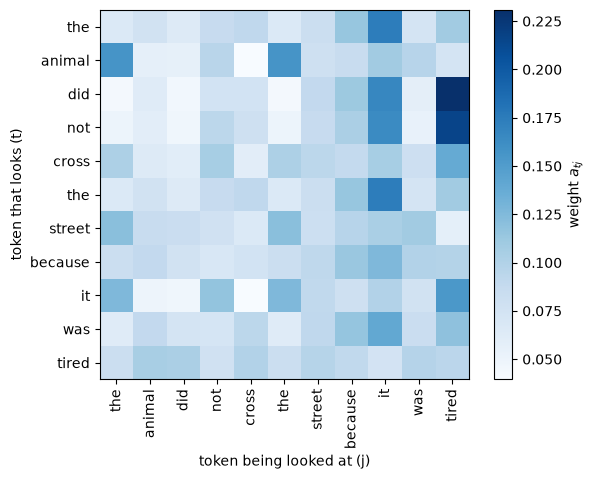

In [4]:
output_loop = np.array([softmax(Q[t] @ K.T / np.sqrt(D_K)) @ V for t in range(T)])
print("rows of A add up to 1:", np.allclose(A.sum(axis=1), 1))
print("same result:", np.allclose(output, output_loop))

plt.imshow(A, cmap="Blues")
plt.xticks(range(T), sentence, rotation=90)
plt.yticks(range(T), sentence)
plt.xlabel("token being looked at (j)")
plt.ylabel("token that looks (t)")
plt.colorbar(label="weight $a_{tj}$")
plt.show()

## 3. Multi-head attention

Each head has its own matrices: $\text{head}_i = \text{Attention}(\mathbf{X}\mathbf{W}_Q^{(i)}, \mathbf{X}\mathbf{W}_K^{(i)}, \mathbf{X}\mathbf{W}_V^{(i)})$.
The heads go side by side and are mixed: $\text{MultiHead}(\mathbf{X}) = [\text{head}_1, \dots, \text{head}_h]\,\mathbf{W}_O$.
In practice one big matrix is computed and split into $h$ slices of size $d_k$.

In [5]:
W_Q_all, W_K_all, W_V_all = (rng.normal(size=(D_MODEL, HEADS * D_K)) / np.sqrt(D_MODEL) for _ in range(3))
W_O = rng.normal(size=(HEADS * D_K, D_MODEL)) / np.sqrt(HEADS * D_K)

Qh, Kh, Vh = ((X @ W).reshape(T, HEADS, D_K).transpose(1, 0, 2) for W in (W_Q_all, W_K_all, W_V_all))
weights = softmax(Qh @ Kh.transpose(0, 2, 1) / np.sqrt(D_K), axis=2)
multi_head = (weights @ Vh).transpose(1, 0, 2).reshape(T, HEADS * D_K) @ W_O

In [6]:
heads = [attention(X @ W_Q_all[:, cols], X @ W_K_all[:, cols], X @ W_V_all[:, cols])[0]
         for cols in np.split(np.arange(HEADS * D_K), HEADS)]
print("same result:", np.allclose(multi_head, np.hstack(heads) @ W_O))

same result: True


## 4. Adding word order

Attention alone ignores order: shuffling the tokens only shuffles the outputs. So a position vector is added, $\mathbf{x}_t \leftarrow \mathbf{x}_t + \mathbf{p}_t$, with
$p_{t,2i} = \sin\!\left(t / 10000^{2i/d_{\text{model}}}\right)$ and $p_{t,2i+1} = \cos\!\left(t / 10000^{2i/d_{\text{model}}}\right)$.

In [7]:
def positional_encoding(length: int, d_model: int) -> np.ndarray:
    """Sinusoidal position vectors, one row per position."""
    angles = np.arange(length)[:, None] / 10000 ** (np.arange(0, d_model, 2) / d_model)
    P = np.zeros((length, d_model))
    P[:, 0::2], P[:, 1::2] = np.sin(angles), np.cos(angles)
    return P


print(positional_encoding(2, 4)[1].round(3))
print("same result:", np.allclose(positional_encoding(2, 4)[1], [np.sin(1), np.cos(1), np.sin(0.01), np.cos(0.01)]))

[0.841 0.54  0.01  1.   ]
same result: True


In [8]:
order = rng.permutation(T)


def self_attention(inputs: np.ndarray) -> np.ndarray:
    """Attention outputs with the matrices of section 2."""
    return attention(inputs @ W_Q, inputs @ W_K, inputs @ W_V)[0]


P = positional_encoding(T, D_MODEL)
print("without positions, shuffling only shuffles the outputs:", np.allclose(self_attention(X[order]), self_attention(X)[order]))
print("with positions, the outputs change:", not np.allclose(self_attention(X[order] + P), self_attention(X + P)[order]))

without positions, shuffling only shuffles the outputs: True
with positions, the outputs change: True


## 5. Causal mask and the next token

A decoder must not look ahead: $\mathbf{A} = \text{softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}} + \mathbf{M}\right)$ with
$M_{tj} = -\infty$ for $j > t$. Row $t$ then equals attention computed on the first $t$ tokens only.

In [9]:
mask = np.triu(np.full((T, T), -np.inf), k=1)
causal_output, causal_A = attention(Q, K, V, mask)

prefix_only = np.array([attention(Q[:t + 1], K[:t + 1], V[:t + 1])[0][t] for t in range(T)])
print("no weight on future tokens:", np.all(causal_A[mask == -np.inf] == 0))
print("same result:", np.allclose(causal_output, prefix_only))

no weight on future tokens: True
same result: True


The last vector $\mathbf{h}_t$ gets one score per vocabulary token: $P(x_{t+1} = w \mid x_1, \dots, x_t) = \text{softmax}(\mathbf{h}_t \mathbf{W} + \mathbf{b})_w$.
Here $\mathbf{h}_t$ is the input plus the masked attention output (a residual connection; the values are the inputs themselves), and a logistic regression learns $\mathbf{W}, \mathbf{b}$.
The cost is the cross-entropy $J = \frac{1}{T-1}\sum_t -\log P(x_{t+1} = \text{real token})$.

In [10]:
text = "the cat sat on the mat . the dog sat on the rug .".split()
words = sorted(set(text))
ids = np.array([words.index(word) for word in text])
inputs = rng.normal(size=(len(words), D_MODEL))[ids] + positional_encoding(len(ids), D_MODEL)

causal = np.triu(np.full((len(ids), len(ids)), -np.inf), k=1)
H = inputs + attention(inputs @ W_Q, inputs @ W_K, inputs, causal)[0]
H_now, next_ids = H[:-1], ids[1:]

language_model = LogisticRegression(max_iter=5000).fit(H_now, next_ids)
P_by_hand = softmax(H_now @ language_model.coef_.T + language_model.intercept_, axis=1)
print("same result:", np.allclose(P_by_hand, language_model.predict_proba(H_now)))

same result: True


In [11]:
real_column = np.searchsorted(language_model.classes_, next_ids)
J_by_hand = -np.mean(np.log(P_by_hand[np.arange(len(next_ids)), real_column]))
print(f"cross-entropy {J_by_hand:.3f} | same result:", np.isclose(J_by_hand, log_loss(next_ids, P_by_hand, labels=language_model.classes_)))
for t in [1, 4]:
    guess = words[language_model.classes_[P_by_hand[t].argmax()]]
    print(f"after '{' '.join(text[:t + 1])}' the model predicts '{guess}'")

cross-entropy 0.456 | same result: True
after 'the cat' the model predicts 'sat'
after 'the cat sat on the' the model predicts 'mat'


## Exercises

1. Remove the division by $\sqrt{d_k}$ in `attention`, set `D_K = 64` and compare the largest weight in each row of $\mathbf{A}$.
2. Divide the scores of the language model by a temperature $\tau$ (0.5, 1, 2) before the softmax and watch how sharp the probabilities get.
3. Plot `positional_encoding(50, 16)` with `plt.imshow` and find which entries change fastest with the position.